## Task 1: Weekly Flu Counts

### Goals

Collect flu case counts for 7 days using a loop, compute **total**, **average**, **minimum**, and **maximum**, and print a formatted weekly summary.

In [ ]:
def read_count(prompt, default):
    while True:
        text = input(prompt)
        if text == "":
            return default
        if text.isdigit():
            return int(text)
        print("  Please enter a non-negative integer.")

In [ ]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
counts = [19, 22, 25, 18, 20, 24, 21]

for d in range(1, 8):
    old = counts[d - 1]
    val = int(read_count(f"Enter flu cases for day {d}: ", old))
    counts[d - 1] = val

print('Total:', sum(counts), ' - ', 'Average:', round(sum(counts) / len(counts)))

In [ ]:
peak = counts.index(max(counts))
low = counts.index(min(counts))

print(f"{'Day':<5}{'Cases':>6}")
for day, c in zip(days, counts):
    print(f"{day:<5}{c:>6}")
print(f"Highest: {days[peak]} ({counts[peak]})   Lowest: {days[low]} ({counts[low]})")

In [ ]:
rolling = []
for i in range(2, len(counts)):
    rolling.append(round((counts[i - 2] + counts[i - 1] + counts[i]) / 3, 2))
print("Mean of rolling 3:", rolling)

### Extended exercises

1. Use pandas to convert the list into a Series and call `.describe()` to get a statistical summary.
2. Plot the 3-day rolling mean of the counts with matplotlib.
3. Detect anomalies where cases differ from the mean by more than 2 × standard deviation.
4. Compare this week's data with the previous week and compute the percent change.
5. Save results to a CSV file using `csv.writer()`.

In [ ]:
def read_count(prompt, default):
    while True:
        text = input(prompt)
        if text == "":
            return default
        if text.isdigit():
            return int(text)
        print("  Please enter a non-negative integer.")

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
counts = [19, 22, 25, 18, 20, 24, 21]

for d in range(1, 8):
    old = counts[d - 1]
    val = int(read_count(f"Enter flu cases for day {d}: ", old))
    counts[d - 1] = val

In [ ]:
import pandas as pd

data = pd.Series(counts)
data.describe()

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
rolling = data.rolling(window=3).mean()

plt.figure(figsize=(10, 5))
plt.plot(days, counts, label="Raw data", color="lightblue", alpha=0.7, marker="o")
plt.plot(days, rolling, label="3-day rolling mean", color="red", linewidth=2, marker="o")
plt.xlabel("Day")
plt.ylabel("Flu cases")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Detect anomalies by differ from mean more than 2 x stadard deviation
# days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
# counts = [19, 22, 25, 18, 20, 24, 21]

std = data.std(ddof=1)
mean = data.mean()
anomalies = []

for day, cases in zip(days, data):
    diff = abs(cases - mean)
    if diff > 2 * std:
        anomalies.append(cases)

print(anomalies)

In [ ]:
# Compare this week's data with the previous week and compute the percent change
# I need a new week data
# So i need to type it
# Hmmmm, I think that I should customize (độ) read_count()

counts = [19, 22, 25, 18, 20, 24, 21]

def read_single_int(prompt, default):
    while True:
        text = input(prompt).strip()
        if text == "":
            return default 
        if text.isdigit(): 
            return int(text)
        print("  Please enter a non-negative integer.")

def read_weekly_counts(days = None, initial_counts = None, no_of_weeks=2):
    if days is None:
        days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

    if initial_counts is None:
        initial_counts = counts.copy()

    current_week_key = f"Week {no_of_weeks}"
    current_counts = []
    print(f"Input data for {current_week_key} (Enter to get the default value)")
    
    for i, day in enumerate(days):
        default_val = initial_counts[i]
        prompt = f"[{current_week_key}] {day} (default {default_val}): "
        val = read_single_int(prompt, default_val)
        current_counts.append(val)
        
    return current_counts

cases_week_2 = read_weekly_counts(no_of_weeks=2)
cases_week_3 = read_weekly_counts(no_of_weeks=3)

In [ ]:
# Now, I need to write a function to compare both of them and show the percentage of differences
cases_week_1 = counts.copy()

import pandas as pd

def compare_weeks_df(prev_week, curr_week, days=None, label_prev="Previous Week", label_curr="This Week"):
    if days is None:
        days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
        
    df = pd.DataFrame({
        label_prev: prev_week,
        label_curr: curr_week
    }, index=days)
    
    df["Diff"] = df[label_curr] - df[label_prev]
    df["% Change"] = (df["Diff"] / df[label_prev]) * 100
    
    df["% Change"] = df["% Change"].round(2)
    return df

compare_weeks_df(cases_week_2, cases_week_3)

## Task 2: Iterative H–M–S Peeling with // and %

### Goals

Convert a total number of seconds into hours, minutes, and seconds using **floor division** (`//`) and **modulus** (`%`).

secs = 9876  # total seconds
h = secs // 3600
rem = secs % 3600
m = rem // 60
s = rem % 60
print(f"{h} hours - {m} minutes - {s} seconds")

In [ ]:
secs = 9876
h = secs // 3600
rem = secs % 3600
m = rem // 60
s = rem % 60
print(f"{h} hours - {m} minutes - {s} seconds")

### Extended exercises

1. Ask the user to input the total seconds.
2. Format as HH:MM:SS using an f-string: `print(f"{h:02d}:{m:02d}:{s:02d}")`.
3. Verify by converting back: `total_check = h*3600 + m*60 + s`.
4. Extend to milliseconds → hours–minutes–seconds–milliseconds.
5. <font color="#C00000">Peel with a **loop**: use the list of units `[("day", 86400), ("hour", 3600), ("minute", 60), ("second", 1)]` and print e.g. `1 day 3 hours 46 minutes 40 seconds` for 100000 s.</font>

In [ ]:
def print_time(h, m, s, d=None, ms=None):
    time = ""
    if d is not None:
        time += f"{d:02d}:"
        
    time += f"{h:02d}:{m:02d}:{s:02d}"
    
    if ms is not None:
        time += f":{ms:02d}"   # thêm dấu ":" để không bị dính liền với giây
        
    print(time)

In [ ]:
secs = int(input("Input your seconds here:") or 9876)

def calculate(secs):
    h = secs // 3600
    m = secs % 3600 // 60
    s = secs % 3600 % 60
    return h, m, s

h, m, s = calculate(secs)
print_time(h, m, s)

In [ ]:
def check_calculate():
    total_check = 3600*h + 60*m + s
    if total_check == secs:
        print("True")
    else:
        print("You'd check your function again!")

check_calculate()

In [ ]:
millisecs = int(input("Input your milliseconds here:") or 9876010)

def calculate_to_milliseconds(millisecs):
    ms = millisecs % 1000
    secs = millisecs // 1000
    h, m, s = calculate(secs)
    return h, m, s, ms

h, m, s, ms = calculate_to_milliseconds(millisecs)
print_time(h, m, s, ms=ms)

In [ ]:
secs = 100000

def peel(secs):
    units = [
        ("day", 86400),
        ("hour", 3600),
        ("minute", 60),
        ("second", 1)
    ]

    vals = []
    for name, value in units:
        count = secs // value
        secs = secs % value
        vals.append(count)
    return vals

d, h, m, s = peel(secs)
print_time(h, m, s, d=d)
print(f"{d} day {h} hours {m} minutes {s} seconds")

## Task 3: Wage Growth per Year (1–10) with 3% Raise

### Goals

Simulate a yearly wage increase with a constant growth rate of 3%. Use a for loop to compute wages for 10 years and display the results in a formatted table.

In [ ]:
starting_wage, rate = 10.0, 0.03

print(f"{'Year':<6}{'Wage ($/hr)':>12}")
for n in range(1, 11):
    w = starting_wage * (1 + rate) ** n
    print(f"{n:<6}{round(w, 2):>12}")

### Extended exercises

1. Allow user input for o, p, and the number of years.
2. Add a column showing the increase each year (difference from the previous year).
3. Plot the wage growth curve using matplotlib.
4. Compare multiple rates (2%, 5%, 8%) on the same graph.
5. Adjust for inflation by subtracting an annual 2% rate to compute the real wage.

In [ ]:
import pandas as pd

In [ ]:
# 1. Allow user input for o, p, and the number of years.
def get_wage_inputs():
    o = float(input("Enter starting wage (o, e.g. 10.0): ") or 10.0)
    p = float(input("Enter annual raise rate (p, e.g. 0.03 for 3%): ") or 0.03)
    years = int(input("Enter number of years (e.g. 10)") or 10)
    return o, p, years

starting_wage, rate, total_years = get_wage_inputs()
print(f"{starting_wage} - {rate} - {total_years}")

In [ ]:
# 2. Add a column showing the increase each year (difference from the previous year).
def calculate_wage_growth(starting_wage = 10.0, rate = 0.03, total_years = 10, include_increase=True):
    wage_records = []
    prev_wage = starting_wage
    for year in range(1, total_years + 1):
        wage = round(starting_wage * (1 + rate) ** year, 2)
        row = [year, wage]
        if include_increase == True:
            wage_diff = round(wage - prev_wage, 2)
            row.append(wage_diff)
        wage_records.append(row)
        prev_wage = wage
    columns = ["Year", "Wage"]
    if include_increase:
        columns.append("Increase")
    return pd.DataFrame(wage_records, columns=columns)

data = calculate_wage_growth(include_increase=True)
data

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# 3. Plot the wage growth curve using matplotlib.


plt.plot(data["Year"], data["Wage"], )
plt.xlabel("Year"); plt.ylabel("Wage")
plt.show()

In [ ]:
# 4. Compare multiple rates (2%, 5%, 8%) on the same graph.
def get_data(rate):
    return calculate_wage_growth(rate=rate, include_increase=False)

rates = [0.02, 0.05, 0.08]
markers = ["o", "s", "^"]

plt.figure(figsize=(8, 5))

for r, m in zip(rates, markers):
    df = get_data(r)
    plt.plot(df["Year"], df["Wage"], marker=m, label=f"{int(r * 100)}% Rate")

plt.xlabel("Year")
plt.ylabel("Wage ($/hr)")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.plot()

In [ ]:
# 5. Adjust for inflation by subtracting an annual 2% rate to compute the real wage.
def get_real_wages(rate, inflation_rate=0.02):
    real_rate = rate - inflation_rate
    return get_data(real_rate)

rates = [0.02, 0.05, 0.08]
markers = ["o", "s", "^"]

plt.figure(figsize=(8, 5))

for r, m in zip(rates, markers):
    df = get_real_wages(r)
    plt.plot(df["Year"], df["Wage"], marker=m, label=f"{int(r * 100)}% Rate")

plt.xlabel("Year")
plt.ylabel("Real Wage ($/hr)")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.plot()

## Task 4: Perfect Number Detector

### Goals

Write a program to check whether a number is a perfect number. Reinforce the use of while loops, modulus (`%`), and paired divisors (`n // i`). Understand the relationship between divisors and sum-of-divisors logic.

> 📌 **Note**
>
> A perfect number is a positive integer that equals the sum of its proper divisors. For example, 6 = 1 + 2 + 3 and 28 = 1 + 2 + 4 + 7 + 14. To find divisors efficiently, only iterate up to √n and add both `i` and `n // i` when `n % i == 0`.
>

In [ ]:
def is_perfect(n: int) -> bool:
    if n < 2:
        return False
    s = 1
    i = 2
    while i * i <= n:
        if n % i == 0:
            s += i
            if i != n // i:
                s += n // i
        i += 1
    return s == n

for n in [6, 28, 12]:
    print(n, is_perfect(n))

6 True
28 True
12 False


### Extended exercises

- Ask the user to input a number and test it using `is_perfect()`.
- List all perfect numbers between 1 and 10000.
- Count how many perfect numbers exist in a given range.
- Add an iteration counter to display how many divisors were checked.
- Plot the distribution of perfect numbers using matplotlib.

In [5]:
# - Ask the user to input a number and test it using `is_perfect()`.
def check_perfect_number():
    while True:
        n = input("Input your number: ")
        if n == "":
            return
        n = int(n)
        if is_perfect(n):
            print(f"  -> {n} is a perfect number")
        else:
            print(f"  -> {n} is not a perfect number")

check_perfect_number()

In [9]:
# - List all perfect numbers between 1 and 10000.
# - Count how many perfect numbers exist in a given range.

def list_in_range(start, end):
    perfect_numbers = []
    for i in range(start, end + 1):
        if is_perfect(i):
            perfect_numbers.append(i)
    return perfect_numbers

print(list_in_range(1, 10000))
print(list_in_range(1, 100000))
    

[6, 28, 496, 8128]
[6, 28, 496, 8128]


In [ ]:
# - Add an iteration counter to display how many divisors were checked.
def is_perfect_with_counter(n: int):
    if n < 2:
        return False, 0
    s = 1
    i = 2
    iterations = 0
    while i * i <= n:
        iterations += 1
        if n % i == 0:
            s += i
            if i != n // i:
                s += n // i
        i += 1
    return s == n, iterations

test_numbers = [6, 28, 496, 8128, 12]

for num in test_numbers:
    perfect, count = is_perfect_with_counter(num)
    status = "is a perfect number" if perfect else "is NOT a perfect number"
    print(f"n = {num:<5}: {status:<24} | Divisors checked: {count} iterations")

n = 6    : is a perfect number      | Divisors checked: 1 iterations
n = 28   : is a perfect number      | Divisors checked: 4 iterations
n = 496  : is a perfect number      | Divisors checked: 21 iterations
n = 8128 : is a perfect number      | Divisors checked: 89 iterations
n = 12   : is NOT a perfect number  | Divisors checked: 2 iterations


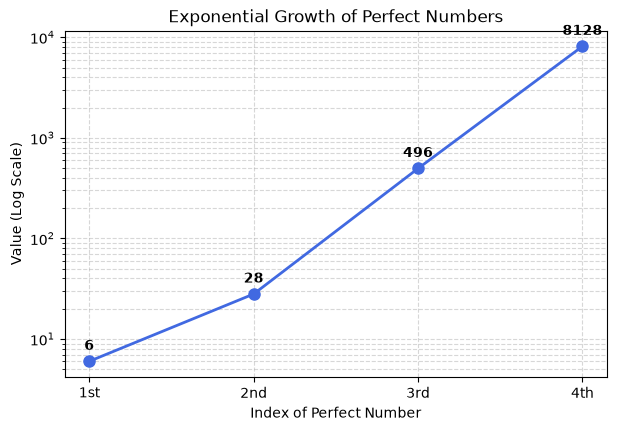

In [12]:
# - Plot the distribution of perfect numbers using matplotlib.
import matplotlib.pyplot as plt

order = ["1st", "2nd", "3rd", "4th"]
values = [6, 28, 496, 8128]

plt.figure(figsize=(7, 4.5))
plt.plot(order, values, marker='o', color='royalblue', linewidth=2, markersize=8)
plt.yscale('log')  # Thang đo logarit để thấy rõ sự tăng trưởng theo cấp số nhân

for i, v in enumerate(values):
    plt.text(i, v * 1.3, str(v), ha='center', fontweight='bold')

plt.xlabel("Index of Perfect Number")
plt.ylabel("Value (Log Scale)")
plt.title("Exponential Growth of Perfect Numbers")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

## Task 5: π Approximation (Leibniz Series)

### Goals

Approximate the value of π using the Leibniz series. Implement a for loop to accumulate alternating terms and observe the convergence behavior as the number of terms increases.

### Extended exercises

1. Allow user input for an error threshold ε and stop when `abs(math.pi - 4*acc) < ε`.
2. Plot the convergence curve (terms vs error) using matplotlib (log scale).
3. Compare with faster series (Nilakantha, Ramanujan).
4. Visualize the alternating signs (+1/1, −1/3, +1/5, …) with a bar chart.

In [ ]:
import math

def pi_leibniz(k_terms: int) -> float:
    sgn = 1.0
    acc = 0.0
    for k in range(k_terms):
        acc += sgn / (2 * k + 1)
        sgn *= -1
    return 4 * acc

for t in [100, 1000, 10000]:
    approx = pi_leibniz(t)
    print(f"terms={t:<6} π≈{approx:.6f} error={abs(math.pi - approx):.6f}")


## Task 6: Fibonacci nth Term and Sequence

### Goals

Generate the Fibonacci sequence and find the nth Fibonacci number. Reinforce the use of for loops and tuple assignment, and compare iterative vs recursive logic.

### Extended exercises

- Allow user input: ask for n and print F(n).
- Display the ratios F(n)/F(n−1) to explore convergence to the Golden Ratio.
- Plot Fibonacci growth using matplotlib (x-axis: n, y-axis: F(n)).
- Compare iterative and recursive implementations and measure their speed.
- Apply modulo operations for pattern- or cryptography-based tasks.

In [ ]:
def fib(n: int) -> int:
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

seq = [fib(i) for i in range(10)]
print(seq)

## Task 7: Binary to Decimal (Positional Weights)

### Goals

Understand how to convert binary numbers to decimal using positional weights. Practice looping through string bits and accumulating positional values.

### Extended exercises

- Allow user input and validate the binary string.
- Compare the result with `int(bits, 2)`.
- Implement the reverse conversion (decimal to binary).
- Handle invalid input gracefully (non-binary characters).
- Plot bit positions and powers of 2 using matplotlib.

In [ ]:
def bin_to_dec(bits: str) -> int:
    val = 0
    for ch in bits:
        val = val * 2 + (1 if ch == '1' else 0)
    return val

print(bin_to_dec('1101'))

## <font color="#C00000">Task 8 – Prime number checker and prime list</font>

<font color="#C00000">Write a function `is_prime(n)` that returns `True` if n is prime. Use a `while` loop that tests divisors only up to √n (as in Task 4). Then print all primes below 100, ten per line, right-aligned in width 4, and the number of primes found.</font>

<font color="#C00000">*(added)*</font>
```text
   2   3   5   7  11  13  17  19  23  29
  31  37  41  43  47  53  59  61  67  71
  73  79  83  89  97
25 primes below 100
```

In [ ]:
def is_prime(n) -> bool:
    i = 2
    while i * i <= n:
        if n % i == 0:
            return False
        i += 1
    return True

# is_prime(100)

In [ ]:
def find_primes(n) -> list:
    if n <= 2:
        print("n must be greater than 3!")
        return

    primes = []
    for i in range(1, n + 1):
        if is_prime(i) == True:
            primes.append(i)
    return primes

# print(find_primes(100))

In [ ]:
def print_primes(n):
    primes = find_primes(n)

    for i in range(0, len(primes), 10):
        sublist = primes[i : i + 10]
        for e in sublist:
            print(f"{e:>4}", end="")
        print()

print_primes(100)

## <font color="#C00000">Task 9 – GCD and LCM with Euclid's algorithm</font>

<font color="#C00000">The greatest common divisor satisfies gcd(a, b) = gcd(b, a % b) and gcd(a, 0) = a. Write `gcd(a, b)` with a `while` loop (no `math.gcd`), print every step, and compute lcm(a, b) = a × b // gcd(a, b). Check your result with `math.gcd`.</font>

<font color="#C00000">*(added)*</font>
```text
a = 84, b = 36
84 % 36 = 12
36 % 12 = 0
gcd = 12, lcm = 252
```

In [ ]:
def swap(a, b):
    temp = a
    a = b
    b = temp

def gcd(a, b) -> int:
    if a < b:
        swap(a, b)

    while b != 0:
        a, b = b, a % b
    return a

def lcm(a, b) -> int:
    return a * b // gcd(a, b)

In [ ]:
a, b = 100, 20
print(f"a = {a}, b = {b}, gcd = {gcd(a,b)}, lcm = {lcm(a,b)}")


## <font color="#C00000">Task 10 – Collatz sequence (while loop)</font>

<font color="#C00000">Start from a positive integer n. If n is even, n ← n // 2; otherwise n ← 3n + 1. Repeat until n = 1. Print the sequence and the number of steps. Then find the starting value below 1000 with the longest sequence.</font>

<font color="#C00000">*(added)*</font>
```text
n = 6: 6 3 10 5 16 8 4 2 1  (8 steps)
Longest below 1000: n = 871 with 178 steps
```

In [ ]:
def collatz(n):
    sequence = []
    sequence.append(n)
    while n != 1:
        if n % 2 == 0:
            n = n // 2
        else:
            n = 3*n + 1
        sequence.append(n)
    return sequence

def print_collatz(n = 6):
    sequence = collatz(n)
    print(f"n = {n}: {sequence}  ({len(sequence)} steps)")

def print_logest_sequence(n = 1000):
    maxN = 1
    maxSteps = 0

    for i in range(1, n+1):
        sequence = collatz(i)
        steps = len(sequence)
        if steps > maxSteps:
            maxSteps = steps
            maxN = i

    print(f"Longest below {n}: n = {maxN} with {maxSteps} steps")

# print_collatz()
print_logest_sequence()